# Main Problem: Identifying the most accurate predictor of stroke from various health factors and demographic indicator

### loading data, and packages

In [413]:
conda install -c conda-forge imbalanced-learn

Solving environment: done

# All requested packages already installed.

Retrieving notices: ...working... done

Note: you may need to restart the kernel to use updated packages.


In [414]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
sb.set()

In [415]:
raw_data = pd.read_csv('healthcare-dataset-stroke-data.csv')

raw_data.info()

# https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset?resource=download

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [416]:
demo_data = pd.DataFrame(raw_data[['gender','age','ever_married','Residence_type','stroke']])
heal_data = pd.DataFrame(raw_data[['hypertension','heart_disease','avg_glucose_level','bmi','smoking_status','stroke']])
demo_data.head()

,gender,age,ever_married,Residence_type,stroke
0,Male,67.0,Yes,Urban,1
1,Female,61.0,Yes,Rural,1
2,Male,80.0,Yes,Rural,1
3,Female,49.0,Yes,Urban,1
4,Female,79.0,Yes,Rural,1


In [417]:
heal_data.head()

,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,stroke
0,0,1,228.69,36.6,formerly smoked,1
1,0,0,202.21,NaN,never smoked,1
2,0,1,105.92,32.5,never smoked,1
3,0,0,171.23,34.4,smokes,1
4,1,0,174.12,24.0,never smoked,1


# Problem part 1: Identifying demographic most at risk of having stroke 

## Problem part 1:Preparing the dataset part 1
### cleaning the data, removing n/a values

In [418]:
# scikit-learn k-fold cross-validation
from numpy import array
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn import datasets
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

#in case 
import re
from collections import Counter
from sklearn.datasets import make_classification
import imblearn
from imblearn.over_sampling import RandomOverSampler, SMOTE
print(imblearn.__version__)

#using unique id to check if every data is unique, to check for duplicates

print("The Data is unique:",pd.Series(raw_data['id']).is_unique)
print('\n')

#checking values of gender
print(demo_data.dtypes)
demo_data['gender'].value_counts()

0.7.0
The Data is unique: True


gender             object
age               float64
ever_married       object
Residence_type     object
stroke              int64
dtype: object


Female    2994
Male      2115
Other        1
Name: gender, dtype: int64

In [419]:
#removing 'Other' from 'gender' treating it as missing value, since it is ambiguious
NewDemoData=demo_data.drop(demo_data.loc[demo_data['gender']=='Other'].index, inplace=False)
NewDemoData

,gender,age,ever_married,Residence_type,stroke
0,Male,67.0,Yes,Urban,1
1,Female,61.0,Yes,Rural,1
2,Male,80.0,Yes,Rural,1
3,Female,49.0,Yes,Urban,1
4,Female,79.0,Yes,Rural,1
...,...,...,...,...,...
5105,Female,80.0,Yes,Urban,0
5106,Female,81.0,Yes,Urban,0
5107,Female,35.0,Yes,Rural,0
5108,Male,51.0,Yes,Rural,0


In [420]:
#checking for missing values 

print(NewDemoData['gender'].value_counts(), '\n')
print(NewDemoData['age'].value_counts(),'\n')
print(NewDemoData['ever_married'].value_counts(),'\n')
print(NewDemoData['Residence_type'].value_counts(),'\n')
print(NewDemoData['stroke'].value_counts())

Female    2994
Male      2115
Name: gender, dtype: int64 

78.00    102
57.00     95
52.00     90
54.00     87
51.00     86
        ... 
1.40       3
0.48       3
0.16       3
0.40       2
0.08       2
Name: age, Length: 104, dtype: int64 

Yes    3353
No     1756
Name: ever_married, dtype: int64 

Urban    2596
Rural    2513
Name: Residence_type, dtype: int64 

0    4860
1     249
Name: stroke, dtype: int64


#### Replace
    Female = 0 
    Male = 1
    
    Married (Yes)= 1
    Not married (No) = 0
    
    Urban = 9 
    Rural = 10

In [421]:
#changing the data into numbers

NewDemoData['gender'].replace(['Male','Female'],[1,0], inplace= True)
NewDemoData['ever_married'].replace(['Yes','No'],[1,0], inplace= True)
NewDemoData['Residence_type'].replace(['Urban','Rural'],[9,10], inplace= True)
NewDemoData

,gender,age,ever_married,Residence_type,stroke
0,1,67.0,1,9,1
1,0,61.0,1,10,1
2,1,80.0,1,10,1
3,0,49.0,1,9,1
4,0,79.0,1,10,1
...,...,...,...,...,...
5105,0,80.0,1,9,0
5106,0,81.0,1,9,0
5107,0,35.0,1,10,0
5108,1,51.0,1,10,0


In [422]:
NewDemoData.dtypes

gender              int64
age               float64
ever_married        int64
Residence_type      int64
stroke              int64
dtype: object

In [423]:
# converting all data type to float

NewDemoData=NewDemoData.astype('float64')
NewDemoData.dtypes

gender            float64
age               float64
ever_married      float64
Residence_type    float64
stroke            float64
dtype: object

In [424]:
NewDemoData.corr()

,gender,age,ever_married,Residence_type,stroke
gender,1.000000,-0.027752,-0.030171,0.006105,0.009081
age,-0.027752,1.000000,0.679084,-0.014031,0.245239
ever_married,-0.030171,0.679084,1.000000,-0.005988,0.108299
Residence_type,0.006105,-0.014031,-0.005988,1.000000,-0.015415
stroke,0.009081,0.245239,0.108299,-0.015415,1.000000


## Problem part 1: Exploratory data analysis / visualization 
### histplot, violinplot, pairplot, heatmap

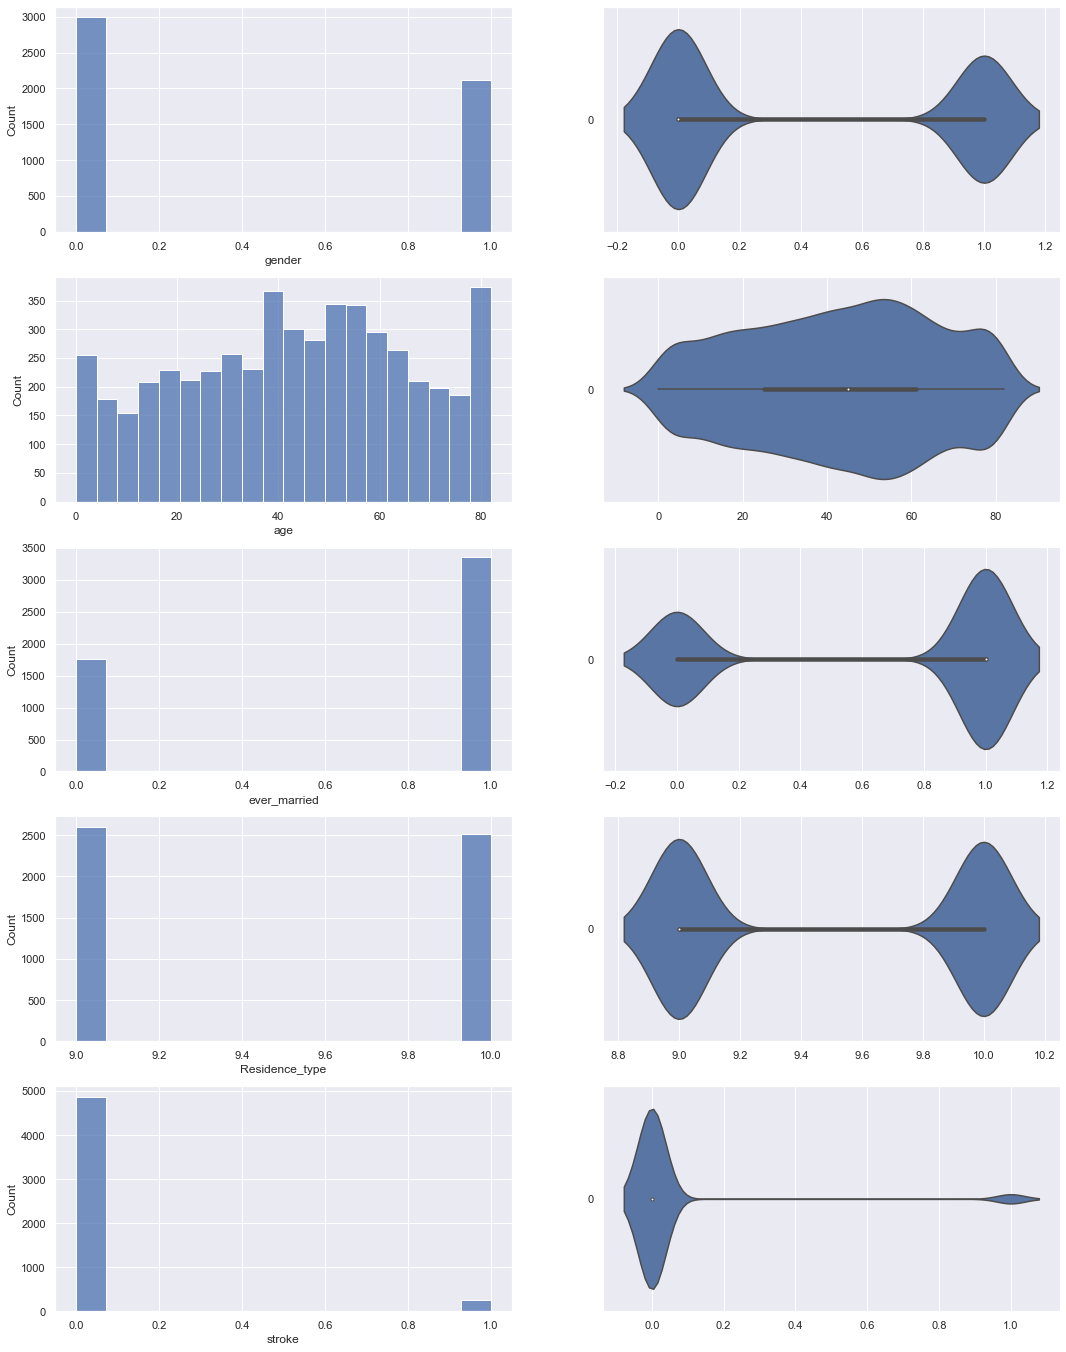

In [425]:
f, axes = plt.subplots(5, 2, figsize=(18, 24))

count = 0
for var in NewDemoData:
    sb.histplot(data = NewDemoData[var], ax = axes[count,0])
    sb.violinplot(data = NewDemoData[var], orient = "h", ax = axes[count,1])
    count += 1

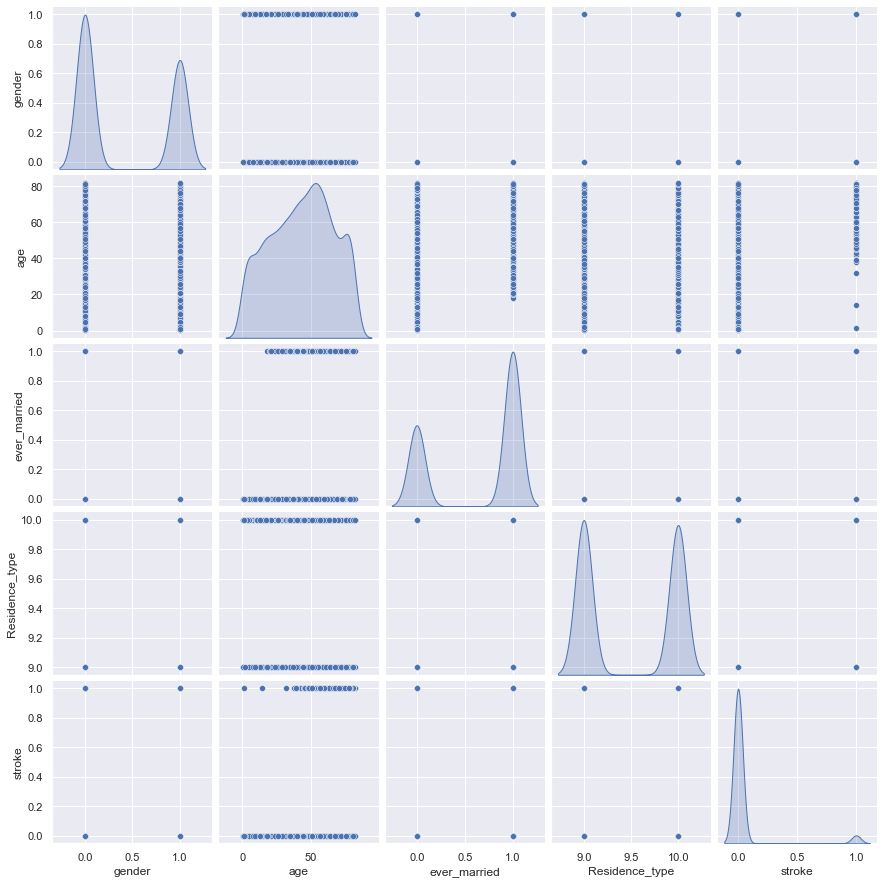

In [426]:
sb.pairplot(data=NewDemoData, diag_kind='kde')

 ### What Data Science method to use?
 Based on the plots, we can use logistic regression, since the outcome we are trying to predict from stroke is  binary: either have stroke, or no stroke

<AxesSubplot:>

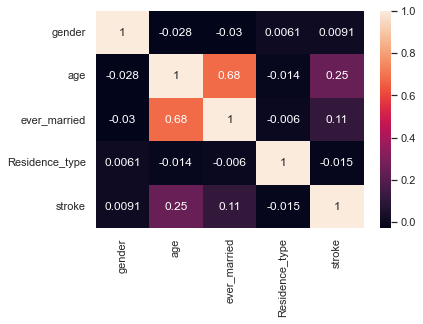

In [427]:
sb.heatmap(NewDemoData.corr(),annot = True)

Hard to read, Nothing is definite. Only from the heat map, age and marriage have the highest magnitude of correlation.
The sample for having stroke is too low ----> need to reset resample the data (oversample the minority)

## Problem part 1: Preparing Data part 2
### SMOTE TECHNIQUE, balancing data (Beyond syllabus)

 since we are using SMOTE we do not need to remove outliers, since the outcome of our data is in minority class, which will cause bias if we remove the outliers. Thus to handler outliers, we will use SMOTE.

In [428]:
Age = pd.DataFrame(NewDemoData['age'])  # predictor---> x
Married = pd.DataFrame(NewDemoData['ever_married'])  #predictor
Stroke = pd.DataFrame(NewDemoData['stroke']) # response--> y

df= Age
df['ever_married']= Married
df['stroke'] = Stroke

print(df)
# Check the stroke distribution
df['stroke'].value_counts(normalize = True)

       age  ever_married  stroke
0     67.0           1.0     1.0
1     61.0           1.0     1.0
2     80.0           1.0     1.0
3     49.0           1.0     1.0
4     79.0           1.0     1.0
...    ...           ...     ...
5105  80.0           1.0     0.0
5106  81.0           1.0     0.0
5107  35.0           1.0     0.0
5108  51.0           1.0     0.0
5109  44.0           1.0     0.0

[5109 rows x 3 columns]


0.0    0.951262
1.0    0.048738
Name: stroke, dtype: float64

/Users/yapakdeeapichart/opt/anaconda3/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='stroke', ylabel='count'>

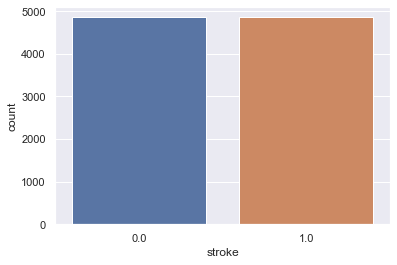

In [429]:
#Importing SMOTE
from imblearn.over_sampling import SMOTE
#Oversampling the data
smote = SMOTE(random_state = 101)
X, y = smote.fit_resample(df[['age', 'ever_married']], df['stroke'])
#Creating a new Oversampling Data Frame

df_oversampler = pd.DataFrame(X, columns = ['age', 'ever_married'])
df_oversampler['stroke'] = y
sb.countplot(df_oversampler['stroke'])

In [430]:
# Importing the splitter, classification model, and the metric
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
#df_oversampler
X_train, X_test, y_train, y_test = train_test_split(df[['age', 'ever_married']], df['stroke'], test_size = 0.4, stratify = df['stroke'], random_state = 101)

In [431]:
#Training with imbalance data
classifier = LogisticRegression()
classifier.fit(X_train, y_train)
print(classification_report(y_test, classifier.predict(X_test)))

              precision    recall  f1-score   support

         0.0       0.95      1.00      0.97      1944
         1.0       0.00      0.00      0.00       100

    accuracy                           0.95      2044
   macro avg       0.48      0.50      0.49      2044
weighted avg       0.90      0.95      0.93      2044



/Users/yapakdeeapichart/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/yapakdeeapichart/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/yapakdeeapichart/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start,

In [432]:
X_oversample, X_test, y_oversample, y_test = train_test_split(df_oversampler[['age', 'ever_married']], df_oversampler['stroke'], test_size = 0.4, stratify = df_oversampler['stroke'], random_state = 101)






In [433]:
#Training with oversampled data
classifier_o = LogisticRegression()
classifier_o.fit(X_oversample, y_oversample)
print(classification_report(y_test, classifier_o.predict(X_test)))

              precision    recall  f1-score   support

         0.0       0.80      0.71      0.75      1944
         1.0       0.74      0.82      0.78      1944

    accuracy                           0.77      3888
   macro avg       0.77      0.77      0.76      3888
weighted avg       0.77      0.77      0.76      3888



## Problem part 1: Use of data science / machine learning to solve the problem 

### Using something beyond the course: Univariate Logistic regression


In [434]:
#create dictionary to store accuracy results of all models

auc_dict={"age":0.0,"ever_married":0.0, "hypertension":0.0,"heart_disease":0.0,"avg_glucose_level":0.0}

Train Set : (7776, 1) (7776,)
Test Set  : (1944, 1) (1944,)


Confusion matrix: 
 [[711 259]
 [218 756]]




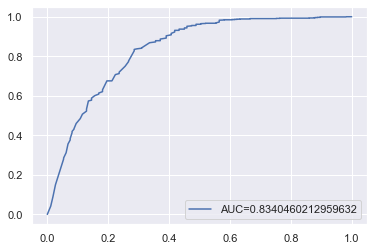

Accuracy:  0.8340460212959632


In [435]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics


#Test and train data split

#define predictor variables and response variable
x = df_oversampler[['age']]
y = df_oversampler['stroke']

#split into training (80%) and testing (20%) sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

# Check the sample sizes
print("Train Set :", x_train.shape, y_train.shape, sep=' ')
print("Test Set  :", x_test.shape, y_test.shape, sep=' ')

# Create a model and train it
model = LogisticRegression(solver='liblinear', C=1.0, random_state=0)
model.fit(x_train, y_train)

#use model to make predictions on test data
y_pred = model.predict(x_test)


# create confusion matrix to see how well model performs
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)

print('\n')
print("Confusion matrix: \n",confusion_matrix)
print('\n')


#define metrics

y_pred_proba = model.predict_proba(x_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

auc = metrics.roc_auc_score(y_test, y_pred_proba)

auc_dict['age']=auc

#create ROC curve

plt.plot(fpr,tpr,label="AUC="+str(auc))

plt.legend(loc=4)

plt.show()

print("Accuracy: ", auc)

Train Set : (7776, 1) (7776,)
Test Set  : (1944, 1) (1944,)


Confusion matrix: 
 [[346 624]
 [103 871]]




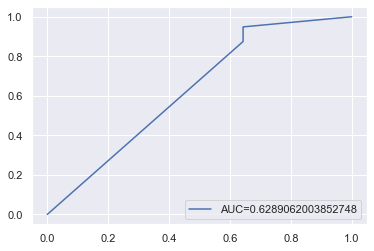

Accuracy:  0.6289062003852748


In [436]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics


#Test and train data split

#define predictor variables and response variable
x = df_oversampler[['ever_married']]
y = df_oversampler['stroke']

#split into training (80%) and testing (20%) sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

# Check the sample sizes
print("Train Set :", x_train.shape, y_train.shape, sep=' ')
print("Test Set  :", x_test.shape, y_test.shape, sep=' ')

# Create a model and train it
model = LogisticRegression(solver='liblinear', C=1.0, random_state=0)
model.fit(x_train, y_train)

#use model to make predictions on test data
y_pred = model.predict(x_test)


# create confusion matrix to see how well model performs
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)

print('\n')
print("Confusion matrix: \n",confusion_matrix)
print('\n')


#define metrics

y_pred_proba = model.predict_proba(x_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

auc = metrics.roc_auc_score(y_test, y_pred_proba)

auc_dict['ever_married']=auc

#create ROC curve

plt.plot(fpr,tpr,label="AUC="+str(auc))

plt.legend(loc=4)

plt.show()

print("Accuracy: ", auc)

# Problem part 2: Identifying best health factors for predicting stroke 

## Problem part 2: Preparing the dataset part 1
### cleaning data: checking for duplicates, removing NaN values, changing data type

In [437]:
#using unique id to check if every data is unique, to check for duplicates

pd.Series(raw_data['id']).is_unique

True

In [438]:
#Since all all data is unique, there are no duplicates


#smoking_status: "formerly smoked", "never smoked", "smokes" or "Unknown",
#"Unknown" in smoking_status means that the information is unavailable for this patient

heal_data.replace('Unknown', np.nan, inplace=True)


In [439]:
heal_data

,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,stroke
0,0,1,228.69,36.6,formerly smoked,1
1,0,0,202.21,NaN,never smoked,1
2,0,1,105.92,32.5,never smoked,1
3,0,0,171.23,34.4,smokes,1
4,1,0,174.12,24.0,never smoked,1
...,...,...,...,...,...,...
5105,1,0,83.75,NaN,never smoked,0
5106,0,0,125.20,40.0,never smoked,0
5107,0,0,82.99,30.6,never smoked,0
5108,0,0,166.29,25.6,formerly smoked,0


In [440]:
#replace smoking_status with numerical values, smokes:2, formerly smokes:1, never smoked:0, so that data can be
#so that data can be visualised and processed later

heal_data['smoking_status'].replace(['smokes','formerly smoked','never smoked'],[1,0.5,0],inplace=True)

#BMI has 4% N/A, and smoking_status has 'Unknown' variables that was replaced as nan
#Next, removing all missing values

cleaned_heal = pd.DataFrame(heal_data.dropna(axis='index', how='any'))

In [441]:
cleaned_heal

,hypertension,heart_disease,avg_glucose_level,bmi,smoking_status,stroke
0,0,1,228.69,36.6,0.5,1
2,0,1,105.92,32.5,0.0,1
3,0,0,171.23,34.4,1.0,1
4,1,0,174.12,24.0,0.0,1
5,0,0,186.21,29.0,0.5,1
...,...,...,...,...,...,...
5100,1,0,71.97,28.3,0.0,0
5102,0,0,77.93,21.7,0.0,0
5106,0,0,125.20,40.0,0.0,0
5107,0,0,82.99,30.6,0.0,0


In [442]:
# checking data types of all data

cleaned_heal.dtypes

hypertension           int64
heart_disease          int64
avg_glucose_level    float64
bmi                  float64
smoking_status       float64
stroke                 int64
dtype: object

In [443]:
# converting all data to the same data type so that we can find correlation and plot graphs later easier

cleaned_heal=cleaned_heal.astype('float64')
cleaned_heal.dtypes

hypertension         float64
heart_disease        float64
avg_glucose_level    float64
bmi                  float64
smoking_status       float64
stroke               float64
dtype: object

## Exploratory data analysis / visualization
### histplot, violinplot, pairplots, heatmap

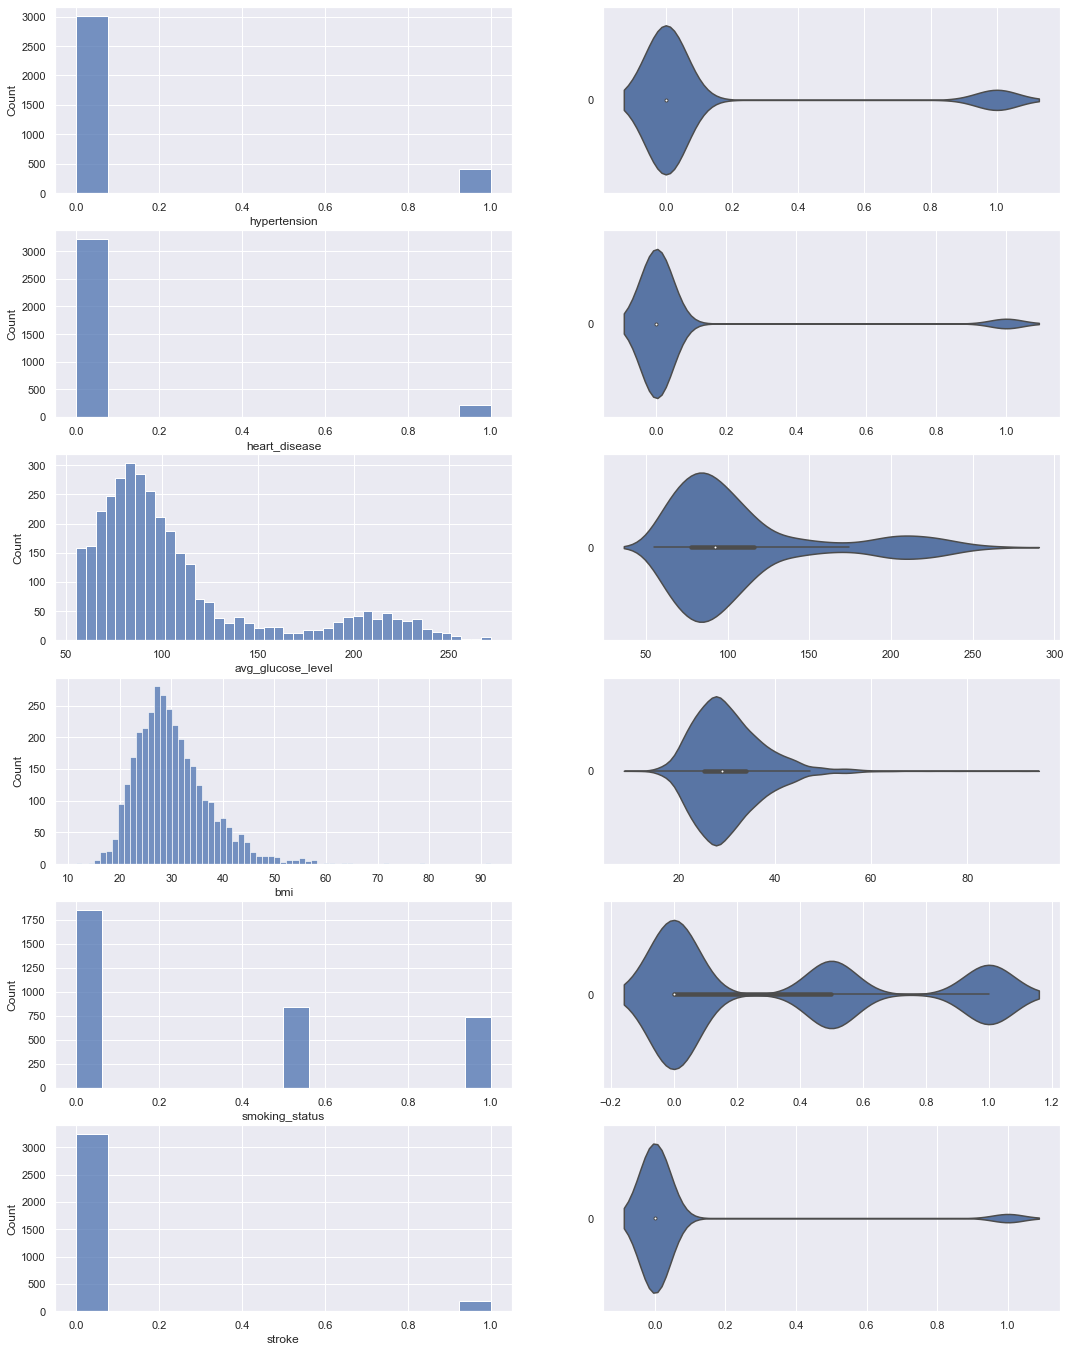

In [444]:
#Using different visualisation methods to identify what may be the best method of modelling,
# linear regression, classifcation trees, clustering & anomaly 


# Draw the distributions of all variables
# using to check for outliers, and to see if data needs balancing

f, axes = plt.subplots(6, 2, figsize=(18, 24))

count = 0
for var in cleaned_heal:
    sb.histplot(data = cleaned_heal[var], ax = axes[count,0])
    sb.violinplot(data = cleaned_heal[var], orient = "h", ax = axes[count,1])
    count += 1

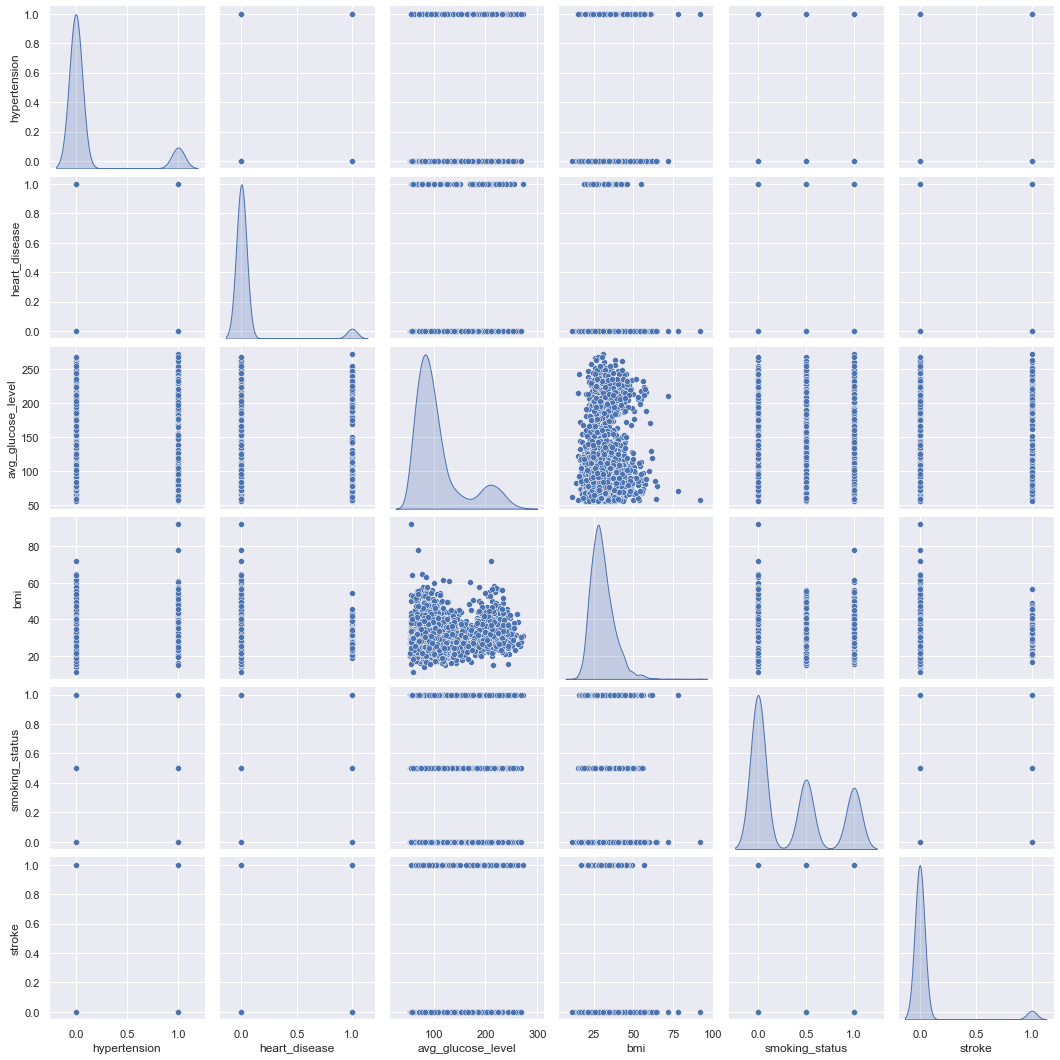

In [445]:
# Draw pairs of variables against one another, to identify if linear regression is viable, 
#or how it can be improved using something not taught in syllabus
sb.pairplot(data=cleaned_heal, diag_kind='kde')

                   hypertension  heart_disease  avg_glucose_level       bmi  \
hypertension           1.000000       0.111707           0.168673  0.132635   
heart_disease          0.111707       1.000000           0.143085  0.001288   
avg_glucose_level      0.168673       0.143085           1.000000  0.156404   
bmi                    0.132635       0.001288           0.156404  1.000000   
smoking_status        -0.001359       0.062517           0.006285  0.037541   
stroke                 0.143647       0.138553           0.140453  0.011673   

                   smoking_status    stroke  
hypertension            -0.001359  0.143647  
heart_disease            0.062517  0.138553  
avg_glucose_level        0.006285  0.140453  
bmi                      0.037541  0.011673  
smoking_status           1.000000  0.022042  
stroke                   0.022042  1.000000  


<AxesSubplot:>

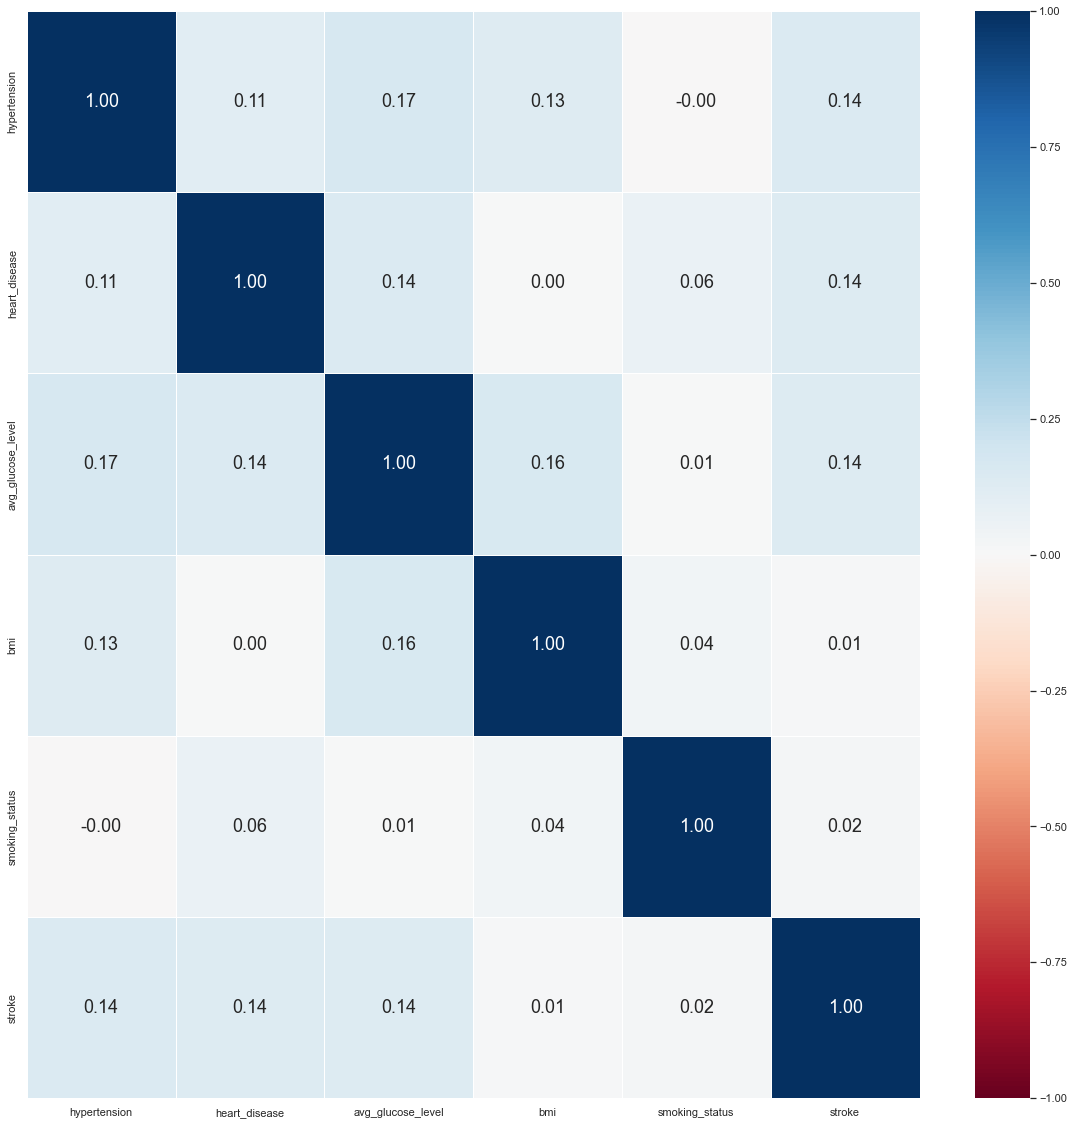

In [446]:
# Correlation Matrix
print(cleaned_heal.corr())

# Heatmap of the Correlation Matrix, to visualise what has the greatest correlation with stroke
f = plt.figure(figsize=(20, 20))
sb.heatmap(cleaned_heal.corr(), vmin = -1, vmax = 1, linewidths = 1,
           annot = True, fmt = ".2f", annot_kws = {"size": 18}, cmap = "RdBu")

 Since hypertension, heart_disease, avg_glucose_level, has the highest/same correlation of 0.14 we will only use them.

### We do not have to remove outliers,since we will be using SMOTE technique, to oversample and balance the data.

Hence, removing outliers is not necessary, since SMOTE will balance the data


### Which data science method to use?

Looking at the pairplot, logistical regression can be used since the outcome to predict will either be have stroke(0) or no stroke(1). Since logistic regression is used to predict true or false outcomes.

## Problem part 2: Preparing the dataset part 2

### oversampling, balancing, SMOTE (beyond the syllabus)

In [447]:
hyper = pd.DataFrame(cleaned_heal['hypertension'])  # predictor---> x
heart = pd.DataFrame(cleaned_heal['heart_disease'])  #predictor
glucose = pd.DataFrame(cleaned_heal['avg_glucose_level'])  #predictor
Stroke = pd.DataFrame(cleaned_heal['stroke']) # response--> y

Df= hyper
Df['heart_disease']= heart
Df['avg_glucose_level'] = glucose
Df['stroke'] = Stroke
print(Df)

# Check the stroke distribution
Df['stroke'].value_counts(normalize = True)

      hypertension  heart_disease  avg_glucose_level  stroke
0              0.0            1.0             228.69     1.0
2              0.0            1.0             105.92     1.0
3              0.0            0.0             171.23     1.0
4              1.0            0.0             174.12     1.0
5              0.0            0.0             186.21     1.0
...            ...            ...                ...     ...
5100           1.0            0.0              71.97     0.0
5102           0.0            0.0              77.93     0.0
5106           0.0            0.0             125.20     0.0
5107           0.0            0.0              82.99     0.0
5108           0.0            0.0             166.29     0.0

[3426 rows x 4 columns]


0.0    0.947461
1.0    0.052539
Name: stroke, dtype: float64

/Users/yapakdeeapichart/opt/anaconda3/lib/python3.9/site-packages/seaborn/_decorators.py:36: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  warnings.warn(


<AxesSubplot:xlabel='stroke', ylabel='count'>

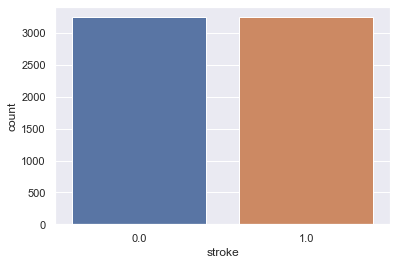

In [448]:
#Importing SMOTE
from imblearn.over_sampling import SMOTE
#Oversampling the data
smote = SMOTE(random_state = 101)
x, Y = smote.fit_resample(Df[['hypertension','heart_disease','avg_glucose_level']], Df['stroke'])
#Creating a new Oversampling Data Frame

Df_oversampler = pd.DataFrame(x, columns = ['hypertension','heart_disease','avg_glucose_level'])
Df_oversampler['stroke'] = Y
sb.countplot(Df_oversampler['stroke'])

In [449]:
# Importing the splitter, classification model, and the metric
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
#df_oversampler
x_train, x_test, Y_train, Y_test = train_test_split(Df[['hypertension','heart_disease','avg_glucose_level']], 
                                                    Df['stroke'],test_size = 0.4, stratify = Df['stroke'],
                                                    random_state = 101)

In [450]:
#Training with imbalance data
classifier = LogisticRegression()
classifier.fit(x_train, Y_train)
print(classification_report(Y_test, classifier.predict(x_test)))

              precision    recall  f1-score   support

         0.0       0.95      1.00      0.97      1299
         1.0       0.00      0.00      0.00        72

    accuracy                           0.95      1371
   macro avg       0.47      0.50      0.49      1371
weighted avg       0.90      0.95      0.92      1371



/Users/yapakdeeapichart/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/yapakdeeapichart/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/Users/yapakdeeapichart/opt/anaconda3/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1318: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start,

In [451]:
x_oversample, x_test, Y_oversample, Y_test = train_test_split(Df_oversampler[['hypertension','heart_disease','avg_glucose_level']], 
                                                    Df_oversampler['stroke'],test_size = 0.4, 
                                                    stratify = Df_oversampler['stroke'], random_state = 101)

In [452]:
#Training with oversampled data
classifier_o = LogisticRegression()
classifier_o.fit(x_oversample, Y_oversample)
print(classification_report(Y_test, classifier_o.predict(x_test)))

              precision    recall  f1-score   support

         0.0       0.65      0.77      0.70      1298
         1.0       0.72      0.59      0.65      1299

    accuracy                           0.68      2597
   macro avg       0.68      0.68      0.68      2597
weighted avg       0.68      0.68      0.68      2597



## Problem part 2: Use of data science / machine learning to solve the problem 

### Using something beyond the course: Univariate Logistic regression



Train Set : (5193, 1) (5193,)
Test Set  : (1299, 1) (1299,)


Confusion matrix: 
 [[568  75]
 [380 276]]




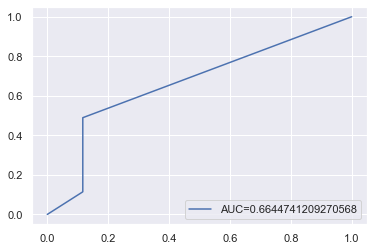

Accuracy:  0.6644741209270568


In [453]:
#Import packages

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics


#Test and train data split

#define predictor variables and response variable
x = Df_oversampler[['hypertension']]
y = Df_oversampler['stroke']

#split into training (80%) and testing (20%) sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

# Check the sample sizes
print("Train Set :", x_train.shape, y_train.shape, sep=' ')
print("Test Set  :", x_test.shape, y_test.shape, sep=' ')

# Create a model and train it
model = LogisticRegression(solver='liblinear', C=1.0, random_state=0)
model.fit(x_train, y_train)

#use model to make predictions on test data
y_pred = model.predict(x_test)


# create confusion matrix to see how well model performs
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)

print('\n')
print("Confusion matrix: \n",confusion_matrix)
print('\n')


#define metrics

y_pred_proba = model.predict_proba(x_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

auc = metrics.roc_auc_score(y_test, y_pred_proba)

auc_dict['hypertension']=auc

#create ROC curve

plt.plot(fpr,tpr,label="AUC="+str(auc))

plt.legend(loc=4)

plt.show()

print("Accuracy: ", auc)

Train Set : (5193, 1) (5193,)
Test Set  : (1299, 1) (1299,)


Confusion matrix: 
 [[609  34]
 [455 201]]




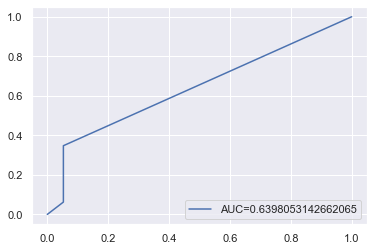

Accuracy:  0.6398053142662065


In [454]:
#Import packages

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics


#Test and train data split

#define predictor variables and response variable
x = Df_oversampler[['heart_disease']]
y = Df_oversampler['stroke']



#split into training (80%) and testing (20%) sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

# Check the sample sizes
print("Train Set :", x_train.shape, y_train.shape, sep=' ')
print("Test Set  :", x_test.shape, y_test.shape, sep=' ')

# Create a model and train it
model = LogisticRegression(solver='liblinear', C=1.0, random_state=0)
model.fit(x_train, y_train)

#use model to make predictions on test data
y_pred = model.predict(x_test)


# create confusion matrix to see how well model performs
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)

print('\n')
print("Confusion matrix: \n",confusion_matrix)
print('\n')


#define metrics

y_pred_proba = model.predict_proba(x_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

auc = metrics.roc_auc_score(y_test, y_pred_proba)

auc_dict["heart_disease"]=auc

#create ROC curve

plt.plot(fpr,tpr,label="AUC="+str(auc))

plt.legend(loc=4)

plt.show()

print("Accuracy: ", auc)

Train Set : (5193, 1) (5193,)
Test Set  : (1299, 1) (1299,)


Confusion matrix: 
 [[513 130]
 [350 306]]




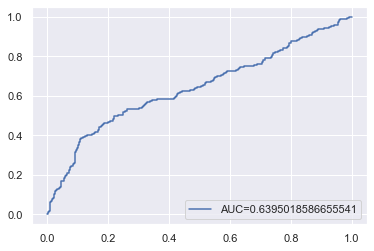

Accuracy:  0.6395018586655541


In [455]:
#Import packages

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics


#Test and train data split

#define predictor variables and response variable
x = Df_oversampler[['avg_glucose_level']]
y = Df_oversampler['stroke']

#split into training (80%) and testing (20%) sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

# Check the sample sizes
print("Train Set :", x_train.shape, y_train.shape, sep=' ')
print("Test Set  :", x_test.shape, y_test.shape, sep=' ')

# Create a model and train it
model = LogisticRegression(solver='liblinear', C=1.0, random_state=0)
model.fit(x_train, y_train)

#use model to make predictions on test data
y_pred = model.predict(x_test)


# create confusion matrix to see how well model performs
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)



print('\n')
print("Confusion matrix: \n",confusion_matrix)
print('\n')



#define metrics

y_pred_proba = model.predict_proba(x_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

auc = metrics.roc_auc_score(y_test, y_pred_proba)

auc_dict["avg_glucose_level"]=auc

#create ROC curve

plt.plot(fpr,tpr,label="AUC="+str(auc))

plt.legend(loc=4)

plt.show()


print("Accuracy: ", auc)

# Summary of problem part 1 and 2, univariate logistic regression

In [456]:
print(auc_dict)

{'age': 0.8340460212959632, 'ever_married': 0.6289062003852748, 'hypertension': 0.6644741209270568, 'heart_disease': 0.6398053142662065, 'avg_glucose_level': 0.6395018586655541}


In [457]:
#sort dictionary to find most accurate model

sorted_auc = {key: val for key, val in sorted(auc_dict.items(), key = lambda ele: ele[1], reverse = True)}
print(sorted_auc) 
print('\n')

for key,value in sorted_auc.items():
    print(key, ':', value)

{'age': 0.8340460212959632, 'hypertension': 0.6644741209270568, 'heart_disease': 0.6398053142662065, 'avg_glucose_level': 0.6395018586655541, 'ever_married': 0.6289062003852748}


age : 0.8340460212959632
hypertension : 0.6644741209270568
heart_disease : 0.6398053142662065
avg_glucose_level : 0.6395018586655541
ever_married : 0.6289062003852748


### Conclusion
Based only on univariate regression of individual demographic and health factors, age is the most accurate predictor of stroke at 83.4% accuracy.

# Problem final part:
### Use of data science: multi-variate logistic regression

In [458]:
# create dictionary to store accuracy measurements

auc_dict_multi = {"health":0.0,"demographic":0.0}

Train Set : (5193, 3) (5193,)
Test Set  : (1299, 3) (1299,)


Confusion matrix: 
 [[500 143]
 [250 406]]




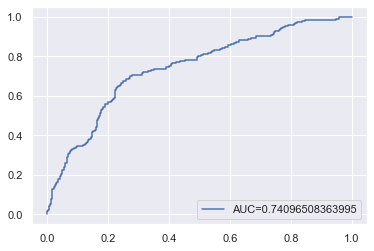

Accuracy:  0.74096508363995


In [459]:
#Logistic regression of all health factors

#Import packages

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics


#Test and train data split

#define predictor variables and response variable
x = Df_oversampler[['avg_glucose_level','heart_disease','hypertension']]
y = Df_oversampler['stroke']

#split into training (80%) and testing (20%) sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

# Check the sample sizes
print("Train Set :", x_train.shape, y_train.shape, sep=' ')
print("Test Set  :", x_test.shape, y_test.shape, sep=' ')

# Create a model and train it
model = LogisticRegression(solver='liblinear', C=1.0, random_state=0)
model.fit(x_train, y_train)

#use model to make predictions on test data
y_pred = model.predict(x_test)


# create confusion matrix to see how well model performs
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)



print('\n')
print("Confusion matrix: \n",confusion_matrix)
print('\n')



#define metrics

y_pred_proba = model.predict_proba(x_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

auc = metrics.roc_auc_score(y_test, y_pred_proba)

auc_dict_multi['health'] = auc

#create ROC curve

plt.plot(fpr,tpr,label="AUC="+str(auc))

plt.legend(loc=4)

plt.show()


print("Accuracy: ", auc)

Train Set : (7776, 2) (7776,)
Test Set  : (1944, 2) (1944,)


Confusion matrix: 
 [[695 275]
 [179 795]]




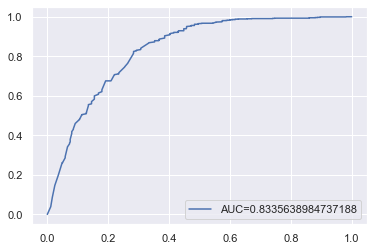

Accuracy:  0.8335638984737188


In [460]:
# Logistic regression of all demographic factors

#Import packages

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics


#Test and train data split

#define predictor variables and response variable
x = df_oversampler[['age','ever_married']]
y = df_oversampler['stroke']

#split into training (80%) and testing (20%) sets
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=0)

# Check the sample sizes
print("Train Set :", x_train.shape, y_train.shape, sep=' ')
print("Test Set  :", x_test.shape, y_test.shape, sep=' ')

# Create a model and train it
model = LogisticRegression(solver='liblinear', C=1.0, random_state=0)
model.fit(x_train, y_train)

#use model to make predictions on test data
y_pred = model.predict(x_test)


# create confusion matrix to see how well model performs
confusion_matrix = metrics.confusion_matrix(y_test, y_pred)



print('\n')
print("Confusion matrix: \n",confusion_matrix)
print('\n')



#define metrics

y_pred_proba = model.predict_proba(x_test)[::,1]

fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)

auc = metrics.roc_auc_score(y_test, y_pred_proba)

auc_dict_multi['demographic'] = auc

#create ROC curve

plt.plot(fpr,tpr,label="AUC="+str(auc))

plt.legend(loc=4)

plt.show()


print("Accuracy: ", auc)

# Summary of final results

In [461]:
for key,value in sorted_auc.items():
    print(key, ':', value)
    
print('\n')

for key,value in auc_dict_multi.items():
    print(key, ':', value)

age : 0.8340460212959632
hypertension : 0.6644741209270568
heart_disease : 0.6398053142662065
avg_glucose_level : 0.6395018586655541
ever_married : 0.6289062003852748


health : 0.74096508363995
demographic : 0.8335638984737188


### For univariate logistic regression

Only age was a good predictor of outcome for stroke, since it was the model using age was the only one exceeding 70%

age : 0.8340460212959632
hypertension : 0.6644741209270568
heart_disease : 0.6398053142662065
avg_glucose_level : 0.6395018586655541
ever_married : 0.6289062003852748

### For multivariate logistic regression

Both health and demographic factors are good predictors, with both exceeding the 70% mark:

health : 0.74096508363995
demographic : 0.8335638984737188

### Comparing both univariate and multivariate

1. Age remains the most accurate at 83.40%, followed by demographic at 83.35%, and health at 74.09%

2. Multivariate logistic regression for health factors creates a more accurate model than its univariate counterparts.

3. Multivariate for demographic is 83.35% which is 0.05% lower than the accuracy of Age.

Data we used:

https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset?resource=download

For logistic regression: 

https://realpython.com/logistic-regression-python/#logistic-regression-in-python-with-scikit-learn-example-1
https://towardsdatascience.com/logistic-regression-for-binary-classification-56a2402e62e6
https://www.nickmccullum.com/python-machine-learning/logistic-regression-python/
https://www.statology.org/logistic-regression-python/

SMOTE technique:

https://www.geeksforgeeks.org/introduction-to-resampling-methods/\
https://towardsdatascience.com/5-smote-techniques-for-oversampling-your-imbalance-data-b8155bdbe2b5\
https://imbalanced-learn.org/stable/over_sampling.html
https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/

Documentation:

https://pandas.pydata.org/docs/
https://scikit-learn.org/stable/user_guide.html
https://imbalanced-learn.org/stable/
https://numpy.org/doc/
https://matplotlib.org/stable/index.html
https://docs.python.org/3/library/re.html
https://docs.python.org/3/library/collections.html
https://docs.python.org/3/index.html
